# Part 2.3 | Bivariate Relationships by Category

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'font.size': 16,
    'axes.titlesize': 20,
    'axes.labelsize': 16,
    'font.style': 'italic',
    'figure.dpi': 400
})

## Create Elections_By_County.csv for Exercise

Source: MIT Election Lab county returns, 2000–2024. `dem_share` is the two-party share, `dem / (dem + rep)`; `total_votes` counts every candidate.

Fixes for the raw file (rebuilt Oct 6, 2026):
- Some states split each county into vote modes (election day, absentee, …). Use the `TOTAL` rows when a county has them; otherwise sum the modes.
- 2024 adds summary rows (`TOTAL VOTES CAST`, `UNDERVOTES`, `OVERVOTES`), reports Rhode Island by town, and shifts FIPS codes in several states. Drop the summary rows, roll towns up to counties, and take each 2024 county's FIPS from its 2020 name.
- 2024 Kansas and Vermont votes are attached to the wrong counties, so they are left missing. Alaska reports legislative districts, not counties, so it is dropped.

In [2]:
# Load raw election data (rows with no party are summary rows, not candidates)
raw = pd.read_csv('../../data/County-Presidential-Election-Returns-2000-2024.csv')
raw = raw.dropna(subset=['county_fips', 'party'])
raw = raw[raw['state_po'] != 'AK']
raw['county_fips'] = raw['county_fips'].astype(int)
raw.loc[(raw['state_po'] == 'RI') & (raw['county_fips'] > 99999), 'county_fips'] //= 100000

# 2024: take each county's FIPS from its 2020 name
name_key = lambda s: s.upper().replace('SAINT', 'ST').replace('.', '').replace("'", '').replace(' ', '')
raw['name_key'] = raw['county_name'].map(name_key)
fips_2020 = raw[raw['year'] == 2020].groupby(['state_po', 'name_key'])['county_fips'].first()
is_2024 = raw['year'] == 2024
raw.loc[is_2024, 'county_fips'] = [fips_2020.get((s, n), f) for s, n, f in
                                   raw.loc[is_2024, ['state_po', 'name_key', 'county_fips']].values]
raw = raw[~(is_2024 & raw['state_po'].isin(['KS', 'VT']))]

# Use TOTAL rows where they exist; otherwise sum the vote modes
raw['is_total'] = raw['mode'].isin(['TOTAL', 'TOTAL VOTES'])
votes = raw[raw['is_total'] | ~raw.groupby(['county_fips', 'year'])['is_total'].transform('any')]

# Two-party Democratic share and total votes
by_party = votes.groupby(['county_fips', 'year', 'party'])['candidatevotes'].sum().unstack('party')
df = pd.DataFrame({
    'dem_share': by_party['DEMOCRAT'] / (by_party['DEMOCRAT'] + by_party['REPUBLICAN']),
    'total_votes': votes.groupby(['county_fips', 'year'])['candidatevotes'].sum(),
}).reset_index()

# Pivot to wide format
elections = df.pivot(index='county_fips', columns='year', values=['dem_share', 'total_votes'])
elections.columns = [f'{col[0]}_{col[1]}' for col in elections.columns]
elections = elections.reset_index()

# Save
elections.to_csv('../../data/Elections_By_County.csv', index=False)
print(f"Saved Elections_By_County.csv: {len(elections)} counties")
elections.head()

Saved Elections_By_County.csv: 3115 counties


,county_fips,dem_share_2000,dem_share_2004,dem_share_2008,dem_share_2012,dem_share_2016,dem_share_2020,dem_share_2024,total_votes_2000,total_votes_2004,total_votes_2008,total_votes_2012,total_votes_2016,total_votes_2020,total_votes_2024
0,1001,0.291822,0.238448,0.259321,0.268006,0.246225,0.274423,0.266411,17208.0,20081.0,23641.0,23932.0,24973.0,27770.0,28281.0
1,1003,0.255099,0.227490,0.240351,0.218190,0.202078,0.227317,0.206524,56480.0,69320.0,81413.0,85338.0,95215.0,109679.0,122249.0
2,1005,0.504473,0.450284,0.492692,0.515791,0.471768,0.461391,0.425850,10395.0,10777.0,11630.0,11509.0,10469.0,10518.0,9855.0
3,1007,0.388085,0.276286,0.268543,0.264219,0.217603,0.208811,0.176151,7101.0,7600.0,8644.0,8420.0,8819.0,9595.0,9257.0
4,1009,0.282079,0.184675,0.147296,0.125174,0.086188,0.096523,0.092231,17973.0,21504.0,24267.0,24006.0,25588.0,27588.0,28163.0


In [3]:
# Checks: national two-party totals (2020: 81.3M D, 74.2M R; 2024: 75.0M D, 77.3M R, less KS + VT)
# and counties whose vote total moved more than 30% between 2020 and 2024
print(by_party.groupby('year')[['DEMOCRAT', 'REPUBLICAN']].sum().div(1e6).round(1).loc[[2020, 2024]])
ratio = elections['total_votes_2024'] / elections['total_votes_2020']
print('Counties with a >30% change in total votes:', int(((ratio < 0.7) | (ratio > 1.3)).sum()))

party  DEMOCRAT  REPUBLICAN
year                       
2020       81.1        74.0
2024       74.1        76.2
Counties with a >30% change in total votes: 1


## Load Data for Figures

In [4]:
# Income data
income = pd.read_csv('../../data/Income_By_County.csv', index_col=0)
income = income[['county_fips', 'Median Household Income']].dropna()
income['county_fips'] = income['county_fips'].astype(int).astype(str)
income.columns = ['county_fips', 'income']

# Elections data
elections = pd.read_csv('../../data/Elections_By_County.csv')
elections['county_fips'] = elections['county_fips'].astype(int).astype(str)

# Merge
data = pd.merge(income, elections, on='county_fips')
data['log_income'] = np.log(data['income'])
data['log_votes'] = np.log(data['total_votes_2024'])
print(f"Merged data: {len(data)} counties")

# Long format for year comparisons
data_long = data.melt(
    id_vars=['county_fips', 'income', 'log_income', 'total_votes_2024', 'log_votes'],
    value_vars=['dem_share_2000', 'dem_share_2024'],
    var_name='Year', value_name='dem_share'
)
data_long['Year'] = data_long['Year'].str.replace('dem_share_', '')
data_long = data_long.dropna()

Merged data: 3104 counties


In [5]:
# Numbers quoted in Notes_2_3.md and concept_2_3.qmd
def r(x, y):
    d = data[[x, y]].dropna()
    return d[x].corr(d[y])
print(f"Counties after merge: {len(data)}")
print(f"Median share: 2000 = {data['dem_share_2000'].median():.0%}, 2024 = {data['dem_share_2024'].median():.0%}")
print(f"r(log size, 2024 share) = {r('log_votes', 'dem_share_2024'):.2f}")
print(f"r(log income, 2000 share) = {r('log_income', 'dem_share_2000'):.2f}")
print(f"r(log income, 2024 share) = {r('log_income', 'dem_share_2024'):.2f}")

Counties after merge: 3104
Median share: 2000 = 41%, 2024 = 29%
r(log size, 2024 share) = 0.53
r(log income, 2000 share) = -0.11
r(log income, 2024 share) = 0.26


## Figure 1: Democratic Share by Year

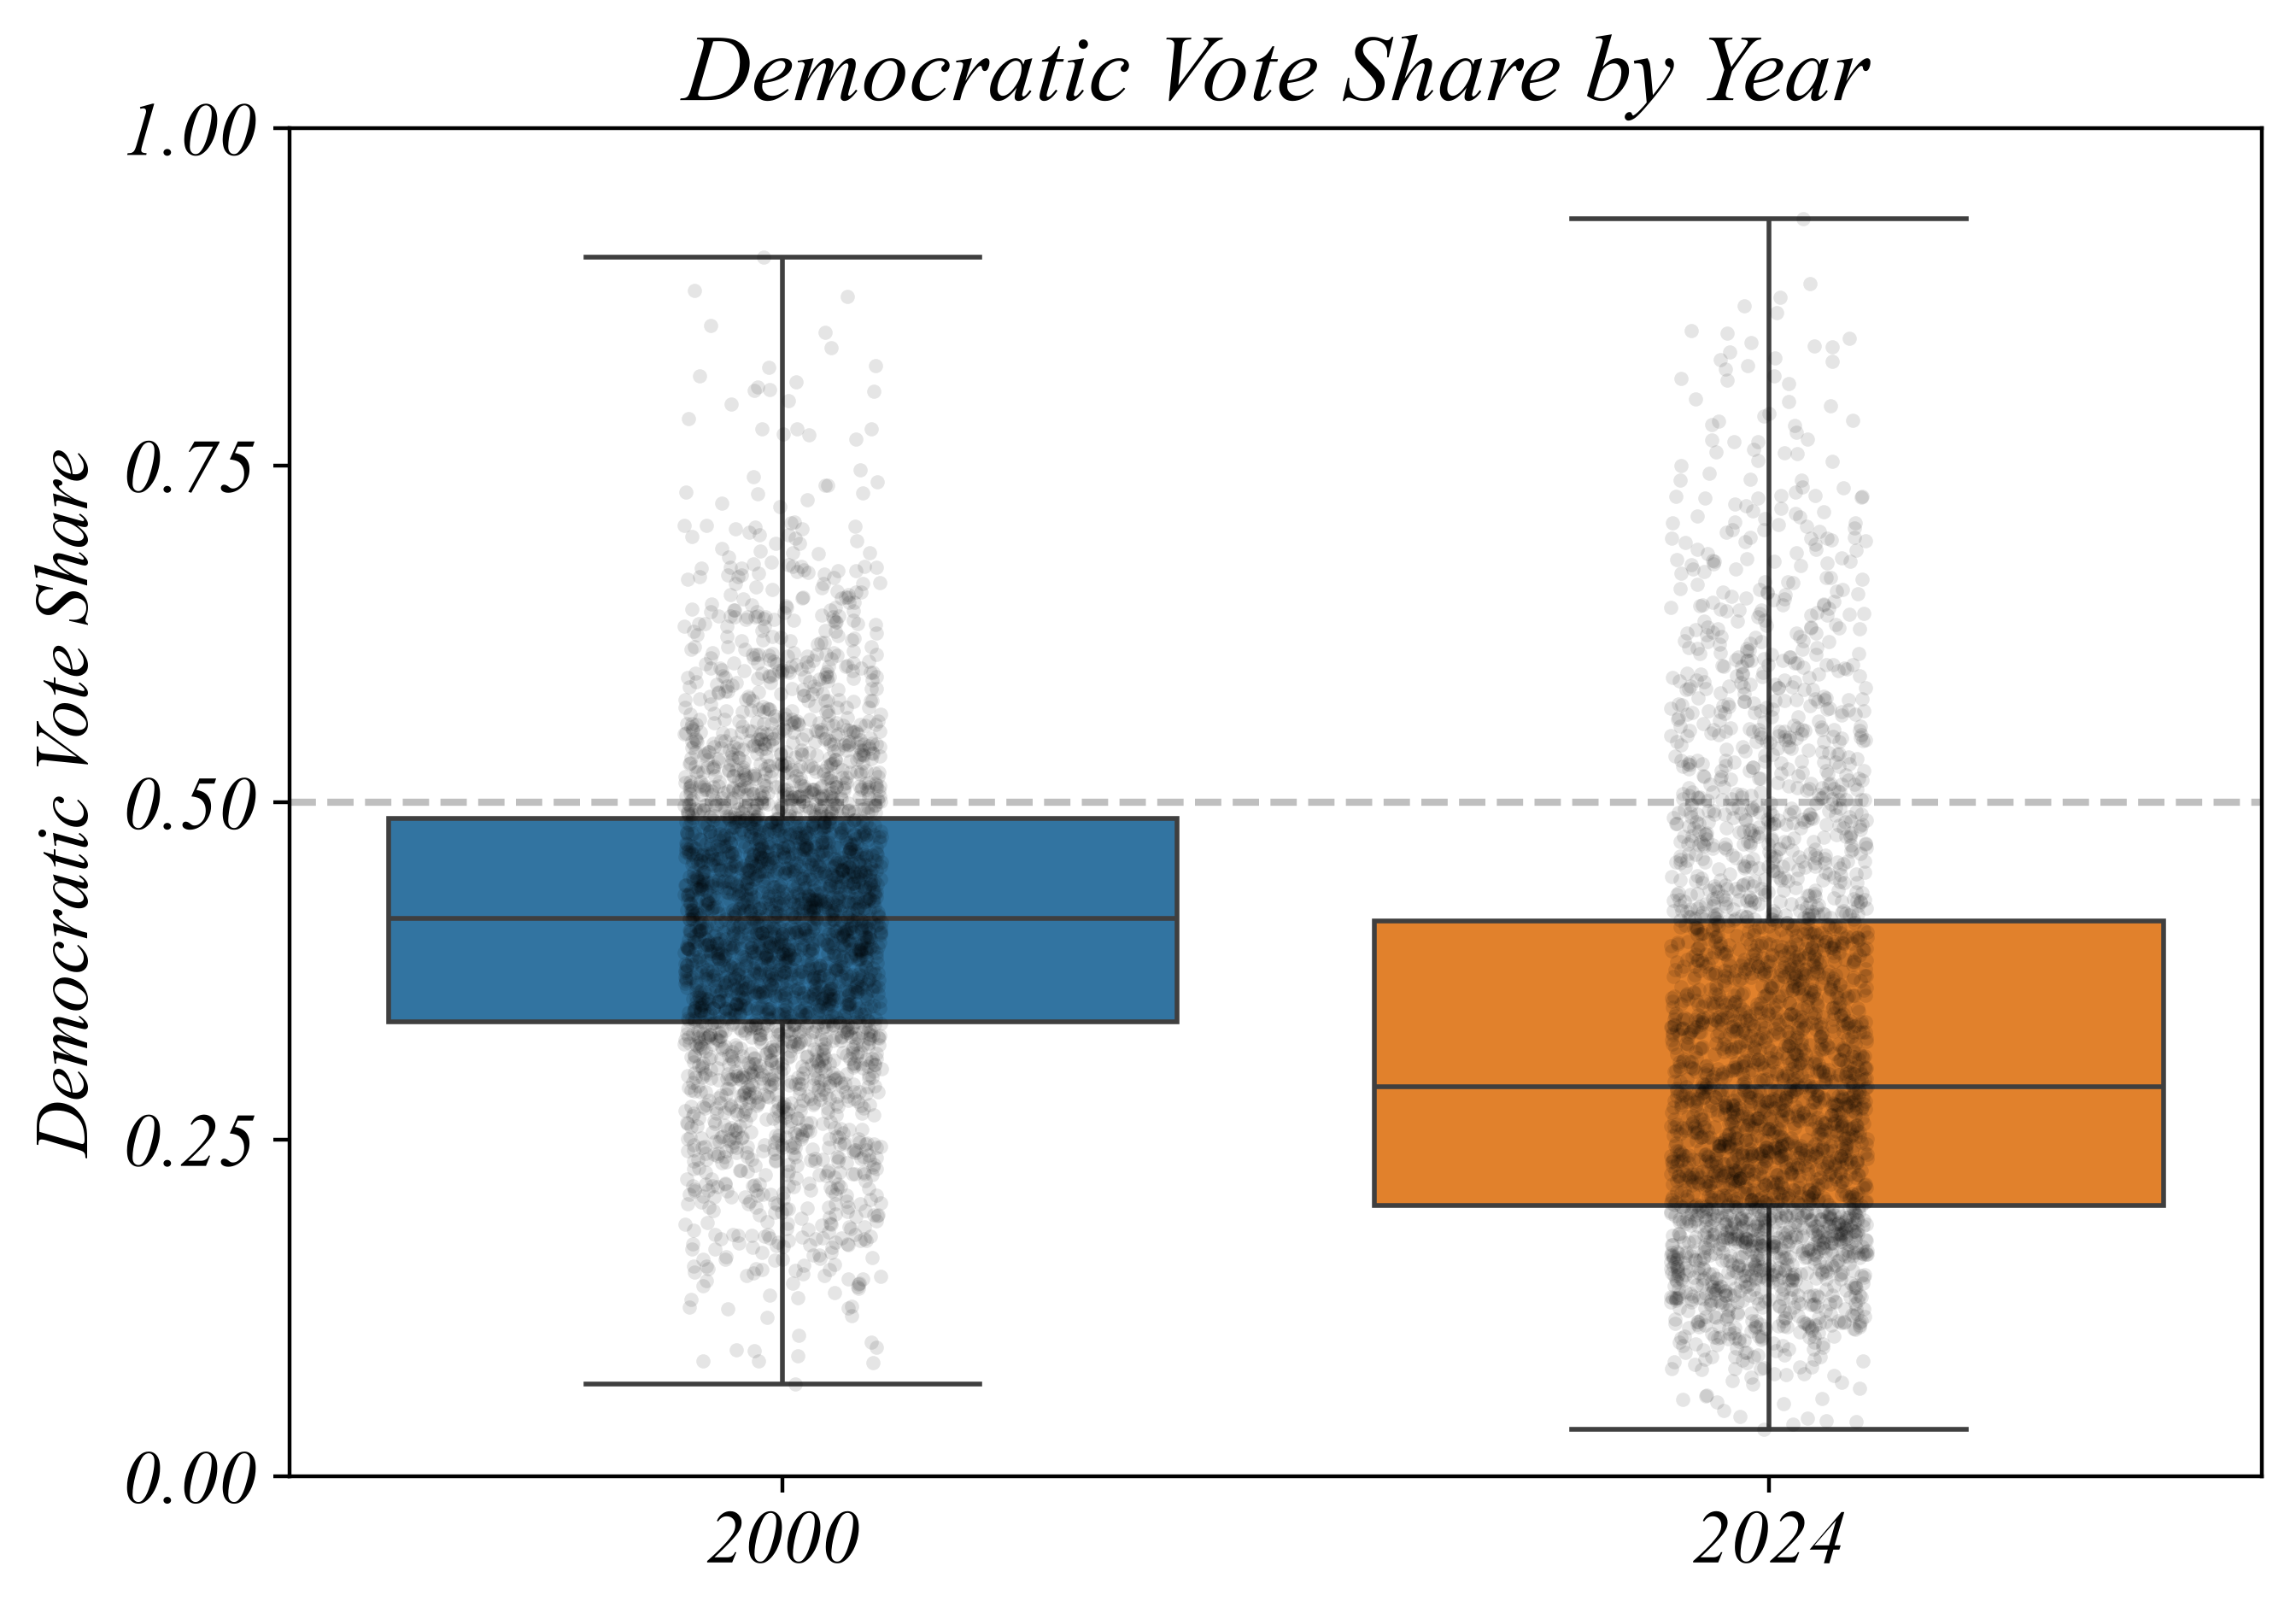

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.boxplot(data=data_long, x='Year', y='dem_share', 
            order=['2000', '2024'], hue='Year', hue_order=['2000', '2024'],
            palette=['C0', 'C1'], whis=(0, 100), ax=ax, legend=False)

sns.stripplot(data=data_long, x='Year', y='dem_share',
              order=['2000', '2024'], color='black', alpha=0.1, size=3, ax=ax)

ax.set_xlabel('')
ax.set_ylabel('Democratic Vote Share')
ax.set_ylim(0, 1)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.axhline(0.5, color='grey', linestyle='--', alpha=0.5)
ax.set_title('Democratic Vote Share by Year')

plt.tight_layout()
plt.savefig('i/dem_share_by_year.png')
plt.show()

## Figure 2: County Size vs Democratic Share

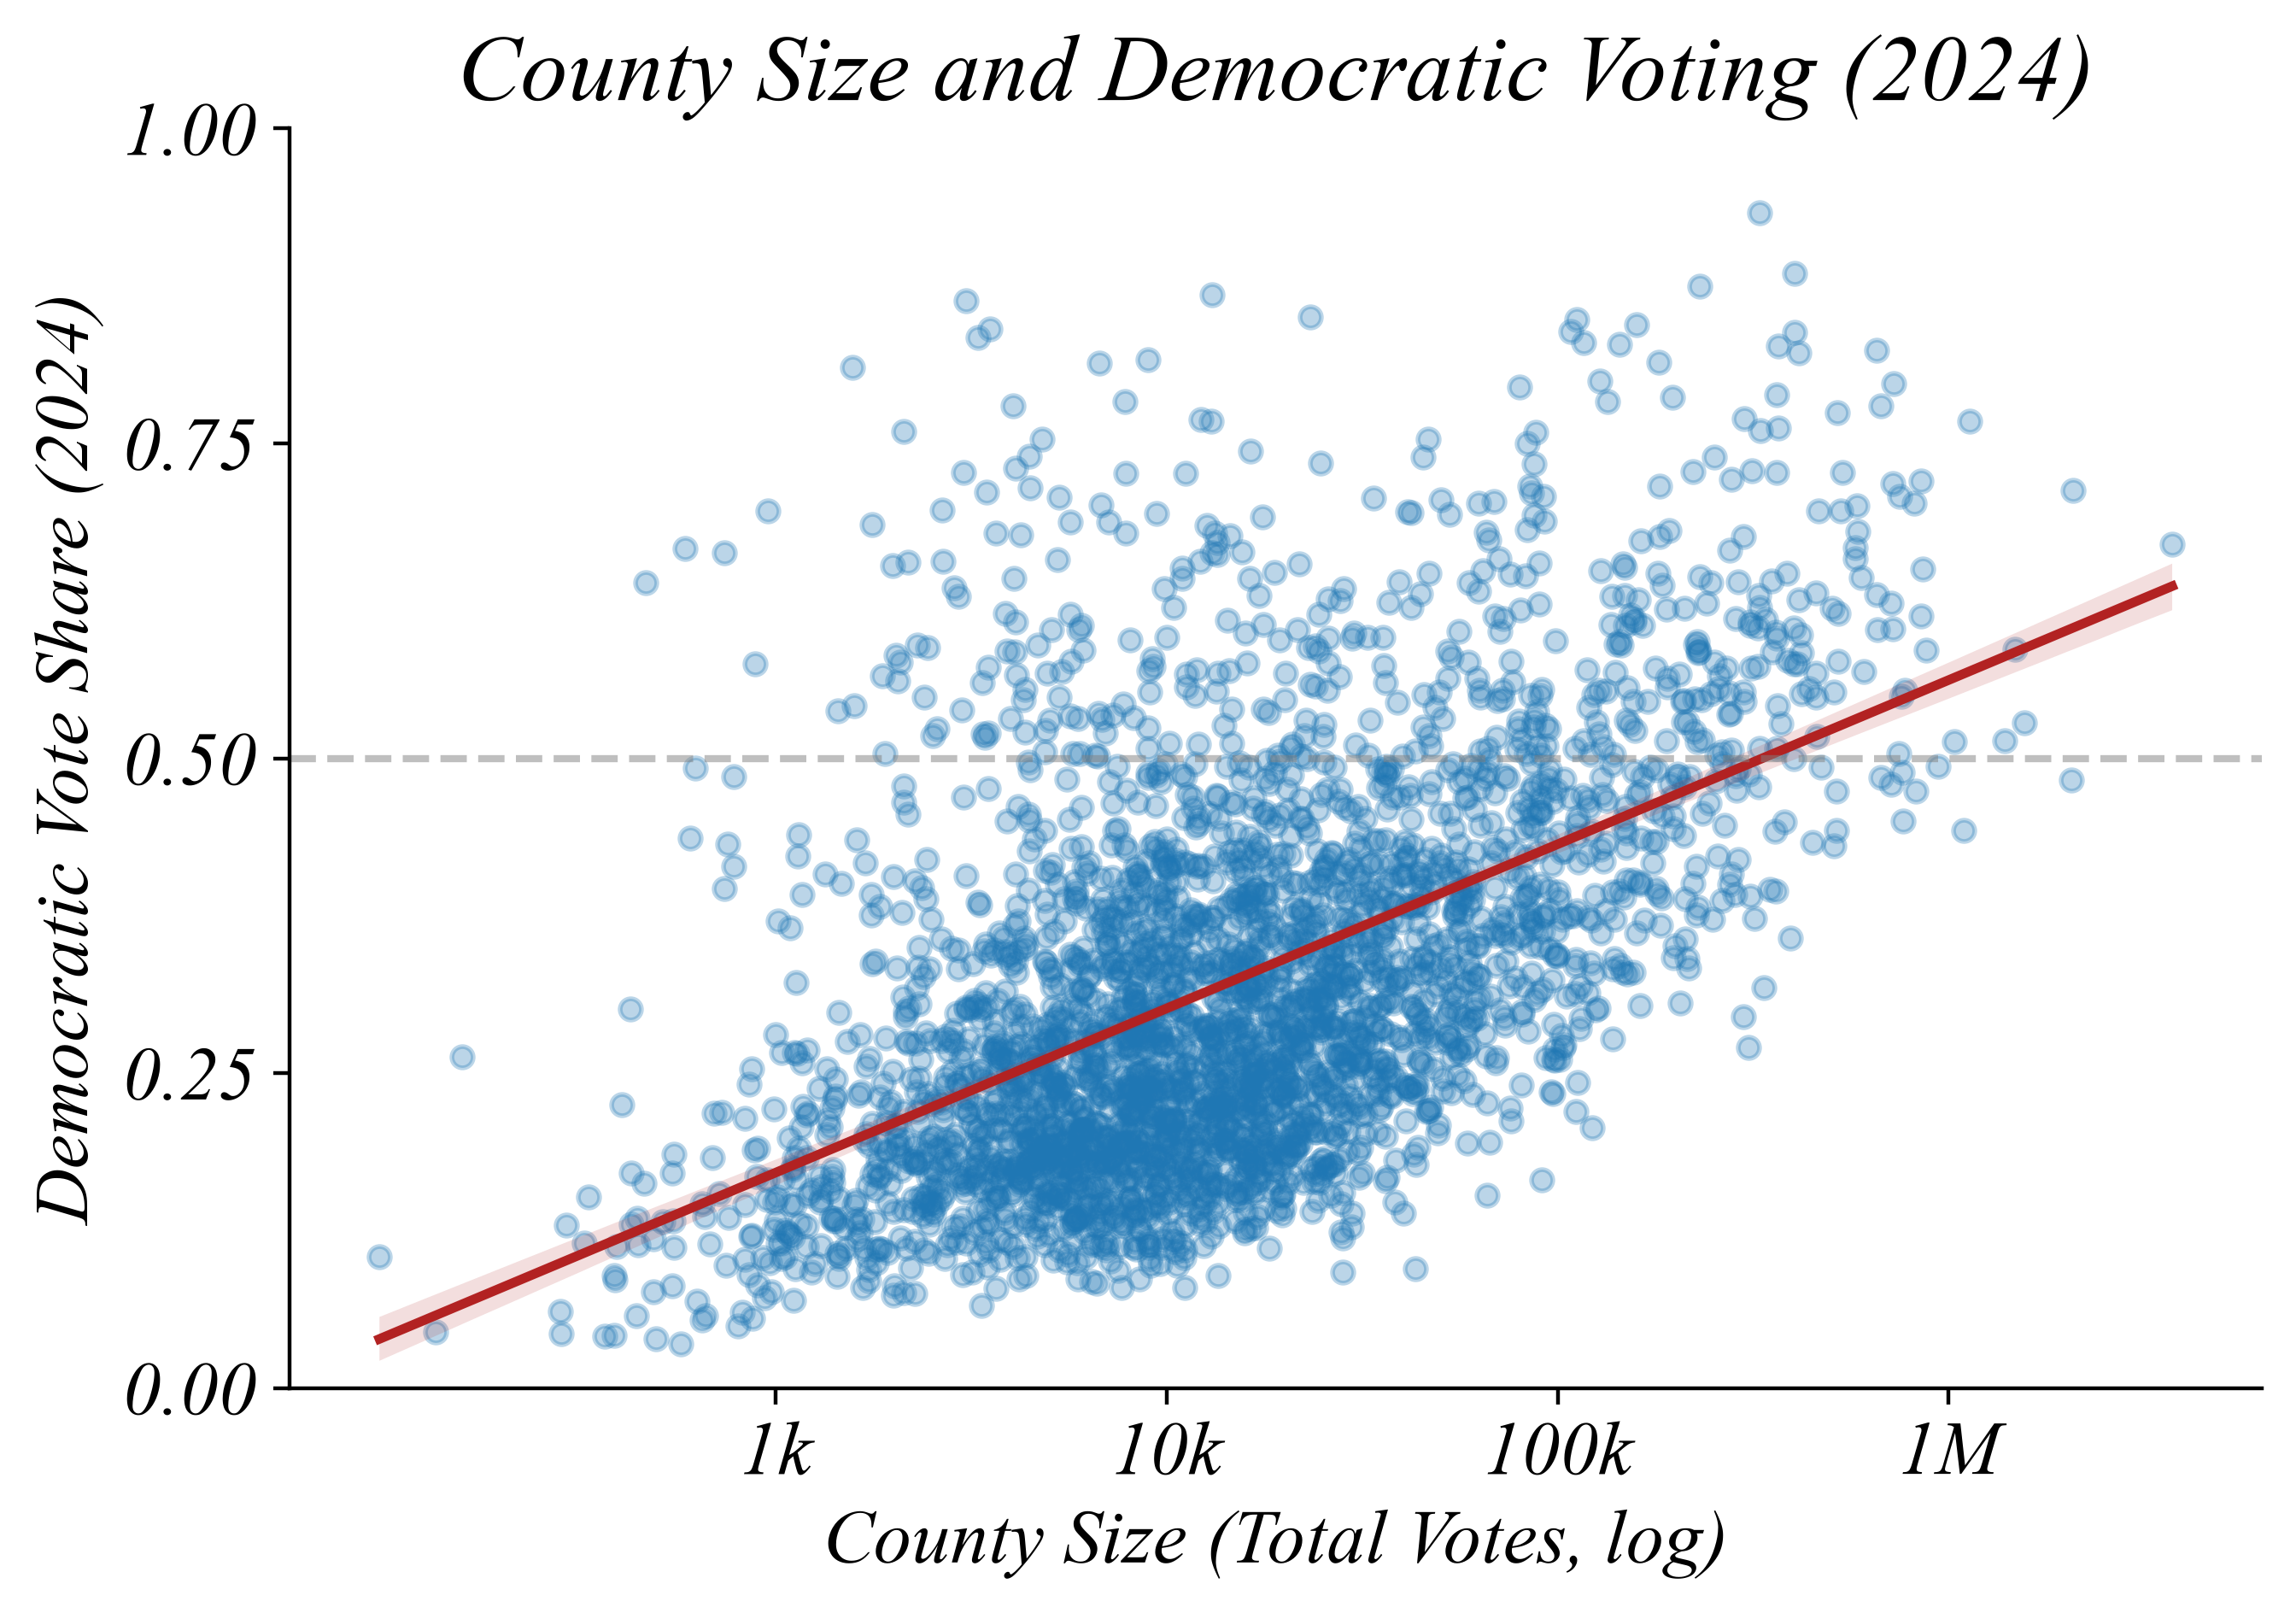

In [7]:
g = sns.lmplot(data=data, x='log_votes', y='dem_share_2024', 
               height=5, aspect=1.4,
               scatter_kws={'alpha': 0.3, 's': 20},
               line_kws={'color': 'firebrick', 'linewidth': 2})

g.ax.set_xlabel('County Size (Total Votes, log)')
g.ax.set_xticks([np.log(1000), np.log(10000), np.log(100000), np.log(1000000)])
g.ax.set_xticklabels(['1k', '10k', '100k', '1M'])

g.ax.set_ylabel('Democratic Vote Share (2024)')
g.ax.set_ylim(0, 1)
g.ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
g.ax.axhline(0.5, color='grey', linestyle='--', alpha=0.5)
g.ax.set_title('County Size and Democratic Voting (2024)')

plt.tight_layout()
plt.savefig('i/size_vs_dem_2024.png')
plt.show()

## Figure 3: Income vs Democratic Share

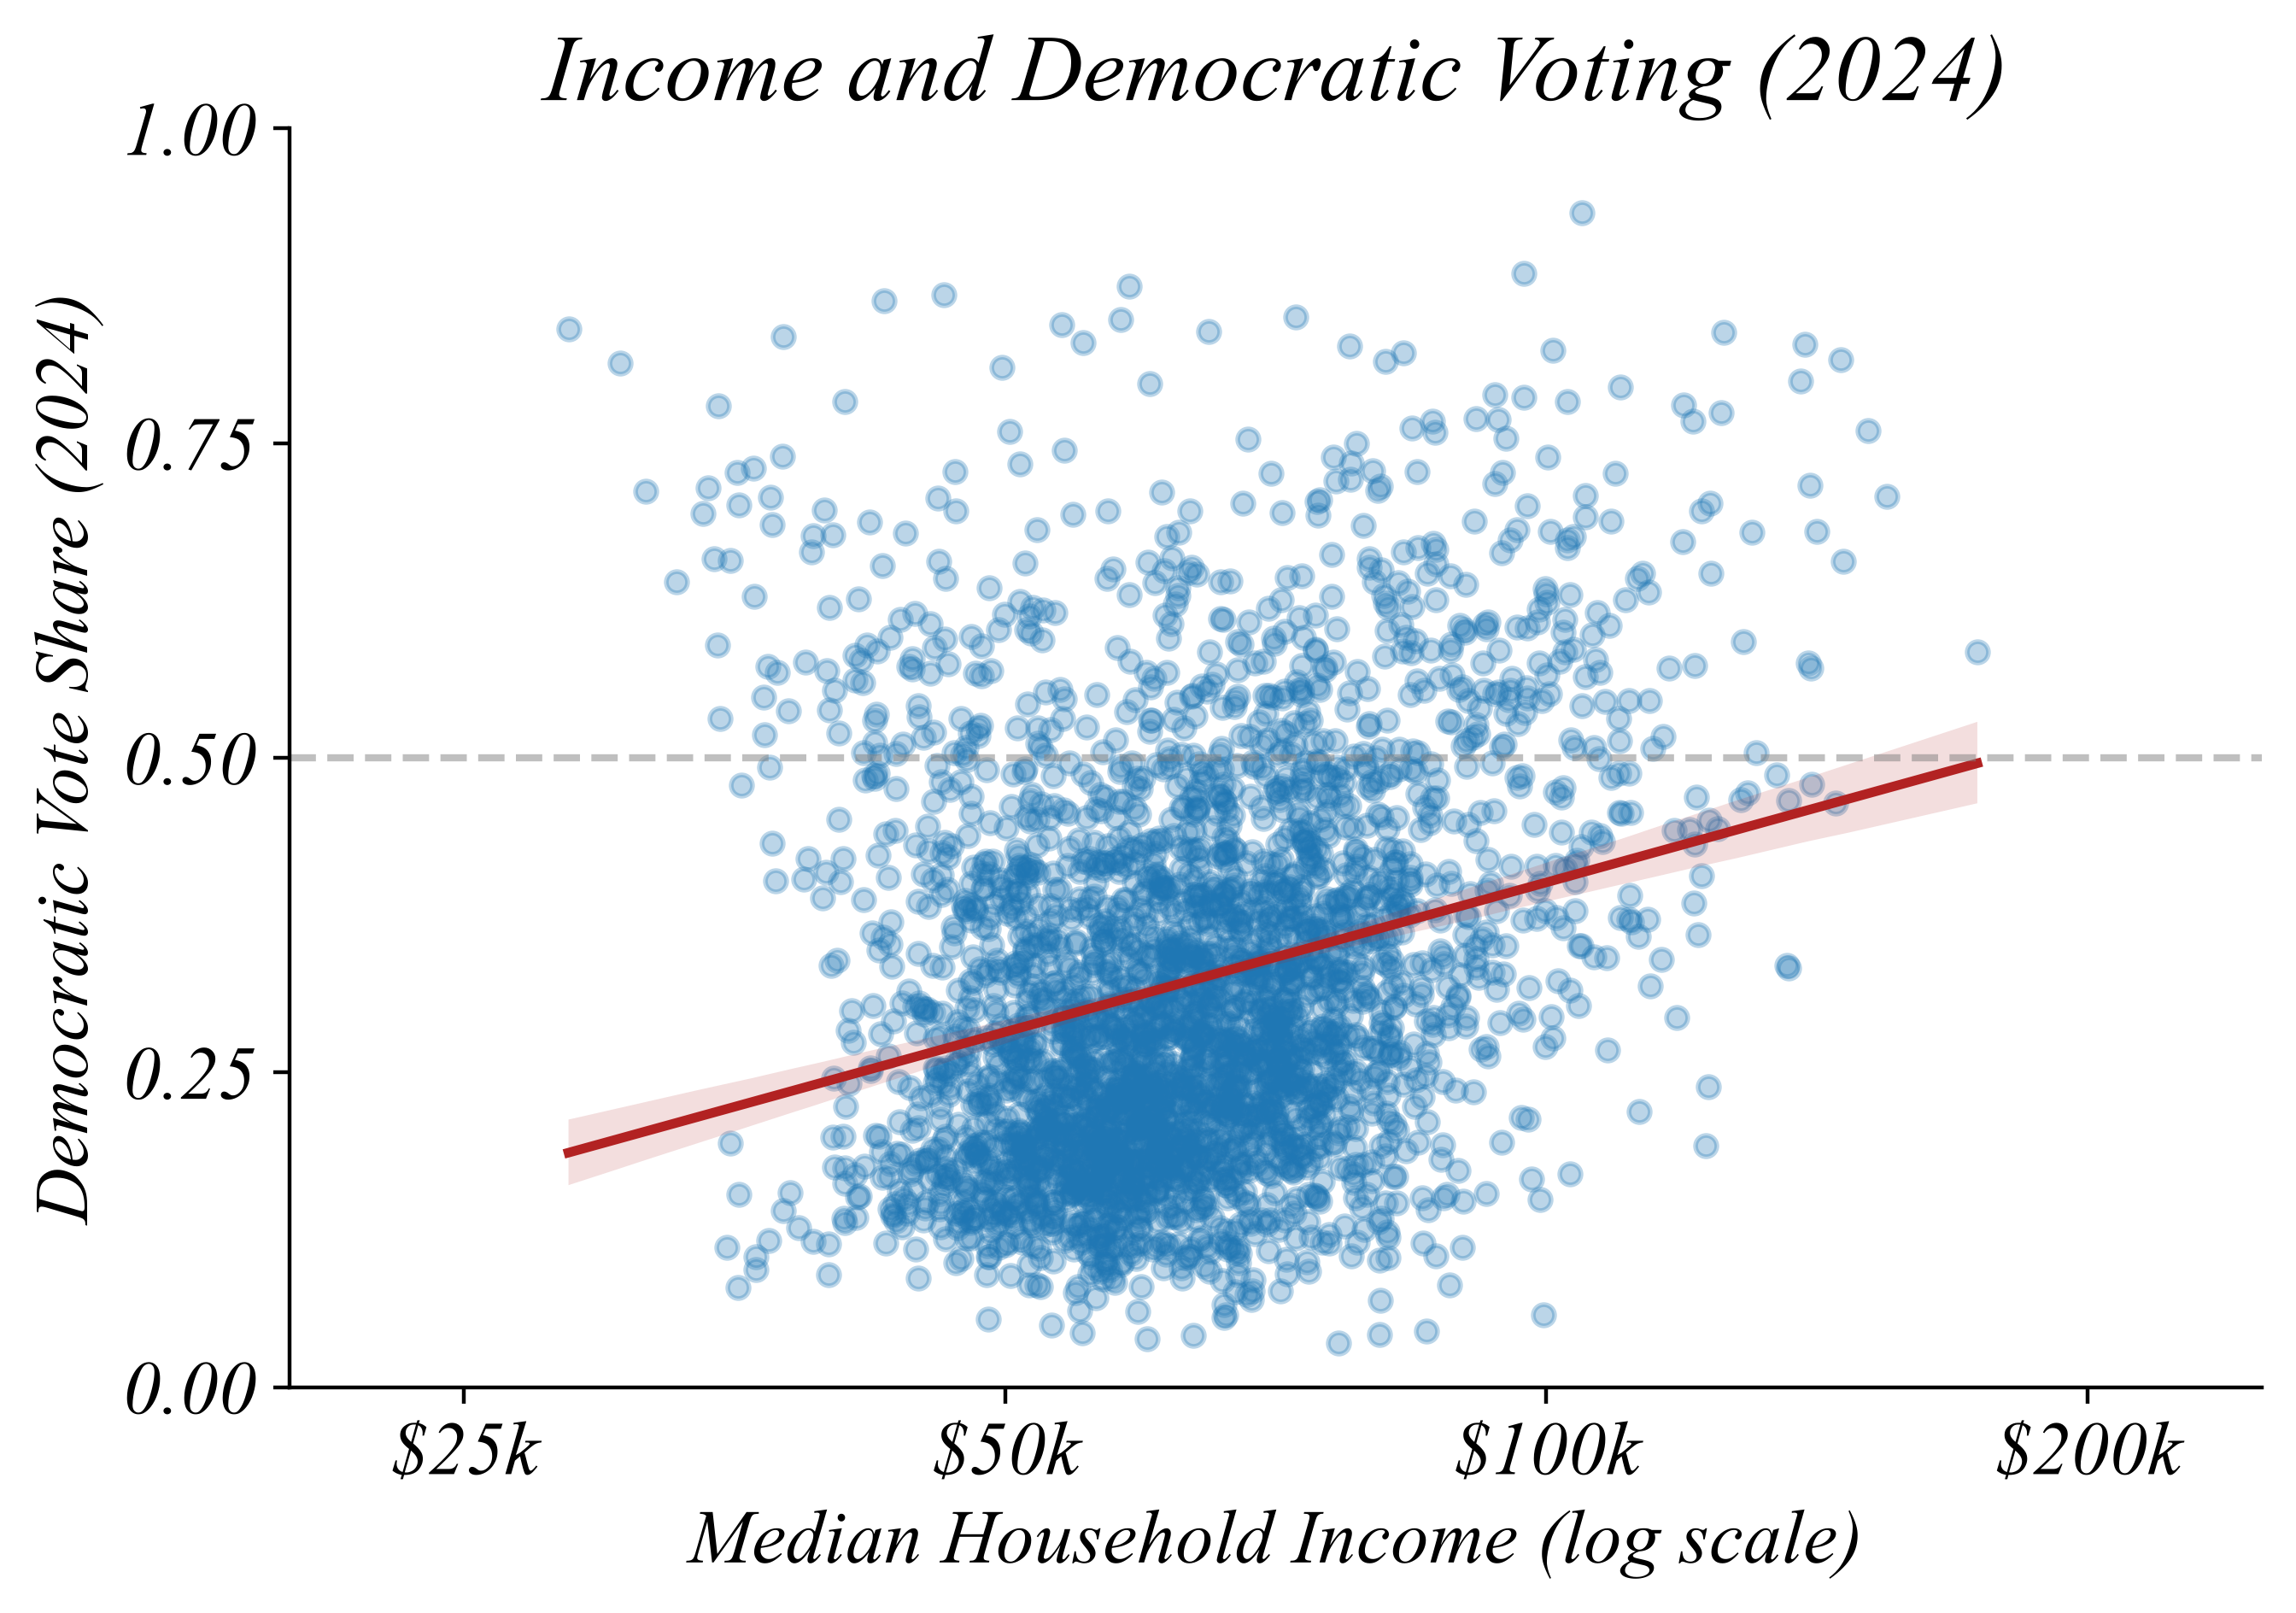

In [8]:
g = sns.lmplot(data=data, x='log_income', y='dem_share_2024', 
               height=5, aspect=1.4,
               scatter_kws={'alpha': 0.3, 's': 20},
               line_kws={'color': 'firebrick', 'linewidth': 2})

income_ticks = [25000, 50000, 100000, 200000]
g.ax.set_xlabel('Median Household Income (log scale)')
g.ax.set_xticks([np.log(x) for x in income_ticks])
g.ax.set_xticklabels(['$25k', '$50k', '$100k', '$200k'])
g.ax.set_xlim(np.log(20000), np.log(250000))

g.ax.set_ylabel('Democratic Vote Share (2024)')
g.ax.set_ylim(0, 1)
g.ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
g.ax.axhline(0.5, color='grey', linestyle='--', alpha=0.5)
g.ax.set_title('Income and Democratic Voting (2024)')

plt.tight_layout()
plt.savefig('i/income_vs_dem_2024.png')
plt.show()

## Figure 4: Income vs Democratic Share by Year

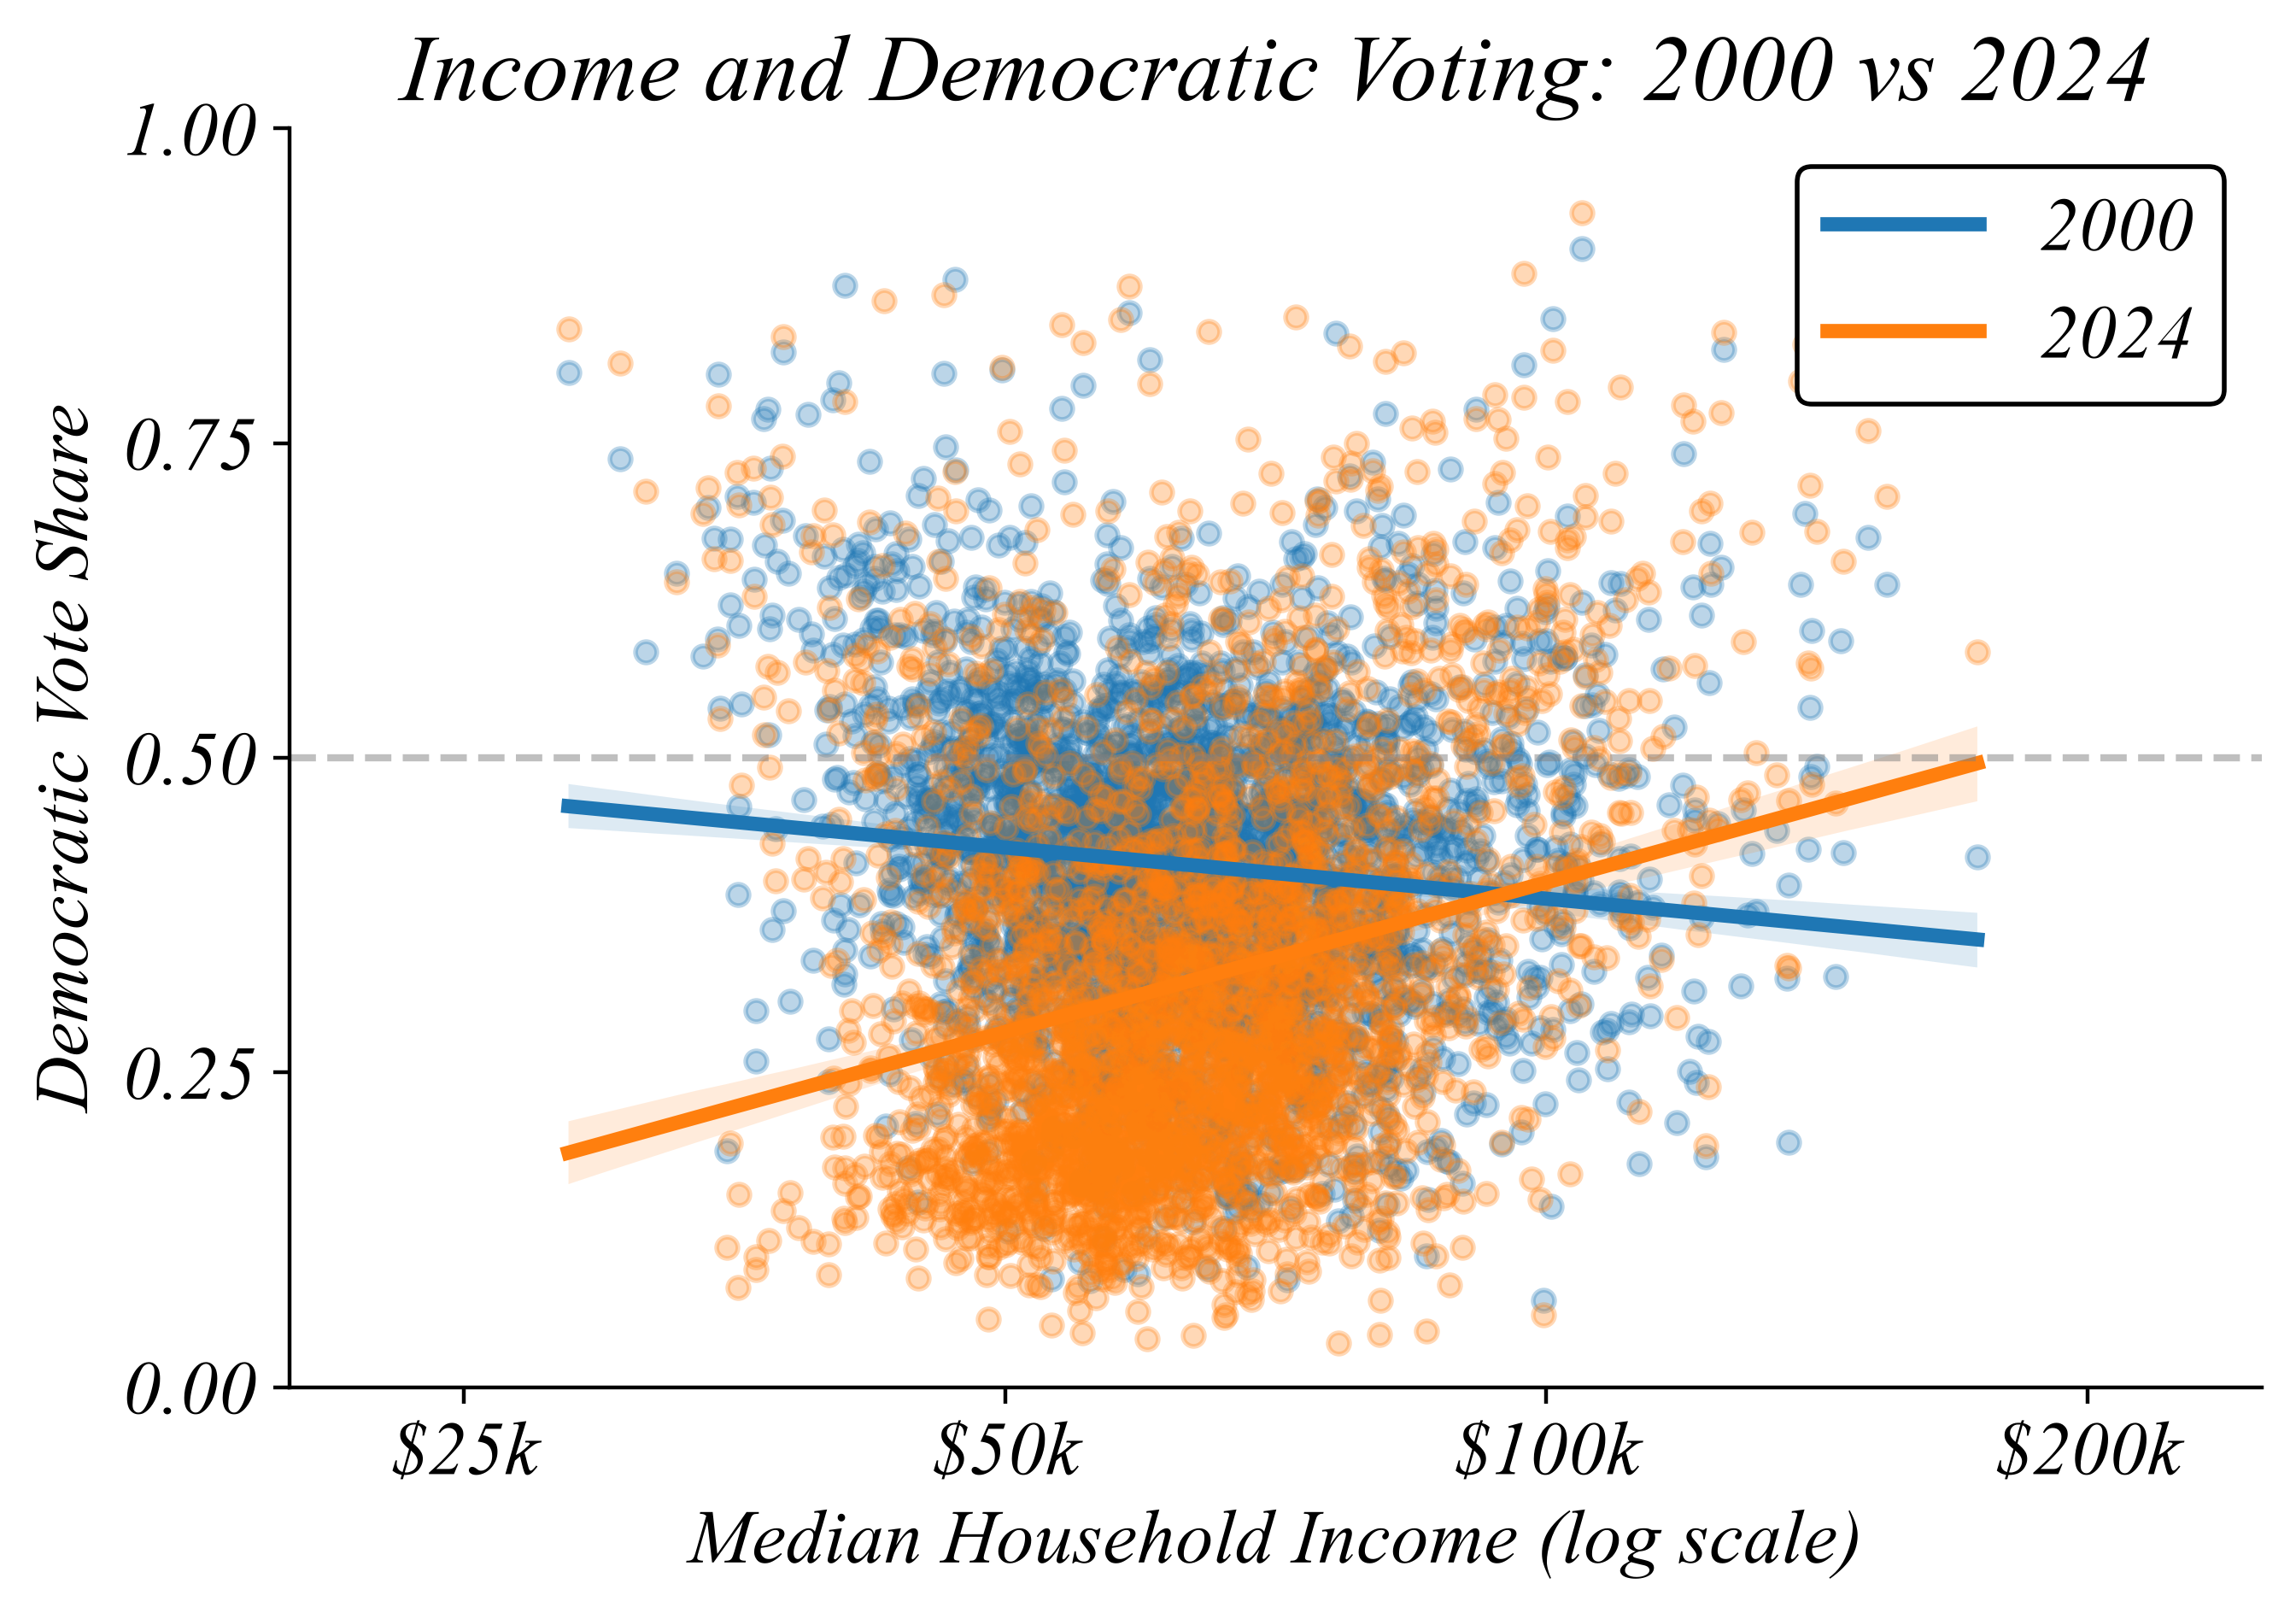

In [9]:
g = sns.lmplot(data=data_long, x='log_income', y='dem_share', hue='Year',
               hue_order=['2000', '2024'], palette=['C0', 'C1'],
               height=5, aspect=1.4,
               scatter_kws={'alpha': 0.3, 's': 20},
               line_kws={'linewidth': 3},
               legend=False)

income_ticks = [25000, 50000, 100000, 200000]
g.ax.set_xlabel('Median Household Income (log scale)')
g.ax.set_xticks([np.log(x) for x in income_ticks])
g.ax.set_xticklabels(['$25k', '$50k', '$100k', '$200k'])
g.ax.set_xlim(np.log(20000), np.log(250000))

g.ax.set_ylabel('Democratic Vote Share')
g.ax.set_ylim(0, 1)
g.ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
g.ax.axhline(0.5, color='grey', linestyle='--', alpha=0.5)
g.ax.set_title('Income and Democratic Voting: 2000 vs 2024')

legend_elements = [Line2D([0], [0], color='C0', linewidth=3, label='2000'),
                   Line2D([0], [0], color='C1', linewidth=3, label='2024')]
g.ax.legend(handles=legend_elements, loc='upper right', frameon=True,
            fancybox=True, edgecolor='black', facecolor='white', framealpha=1)

plt.tight_layout()
plt.savefig('i/income_vs_dem_by_year.png')
plt.show()